# Lab 13-06 · Reflection and Transmission of Waves

Companion to [chapter 13-06](../../chapters/13-06-reflection-and-transmission.md). Four parts: standing waves in front of a boundary; the Fresnel reflectances against angle; coatings and radomes by the transfer-matrix method; and the exact shielding effectiveness of a metal foil. Run the cells in order.

In [1]:
import cmath, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
eps0, mu0 = 8.8541878128e-12, 4e-7 * math.pi
c0, eta0 = 1 / math.sqrt(mu0 * eps0), math.sqrt(mu0 / eps0)

def stack(f, layers, eta_in=eta0, eta_out=eta0):
    '''Normal-incidence reflection and transmission of a stack of (eta, k, d) layers, by ABCD matrices.'''
    M = np.eye(2, dtype=complex)
    for eta, k, d in layers:
        b = k * d
        M = M @ np.array([[cmath.cos(b), 1j * eta * cmath.sin(b)], [1j * cmath.sin(b) / eta, cmath.cos(b)]])
    A, B, C, D = M.ravel()
    Zin = (A * eta_out + B) / (C * eta_out + D)
    return (Zin - eta_in) / (Zin + eta_in), 2 * eta_out / (A * eta_out + B + eta_in * (C * eta_out + D))

def dielectric(er, f, d):
    n = math.sqrt(er); return (eta0 / n, 2 * math.pi * f * n / c0, d)

def metal(sigma, f, d):
    w = 2 * math.pi * f
    k = cmath.sqrt(-1j * w * mu0 * sigma); k = -k if k.imag > 0 else k
    return (cmath.sqrt(1j * w * mu0 / sigma), k, d)

## Part 1 · Standing waves

The total field in front of a boundary is $\lvert e^{jkz} + \Gamma e^{-jkz}\rvert$ times the incident amplitude ($z$ measured toward the source). Plot it for glass, a medium with $\varepsilon_r$ = 4, water ($\varepsilon_r$ = 81) and a perfect conductor.

**Predict first:** for each, where is the field smallest, and what is the standing-wave ratio?

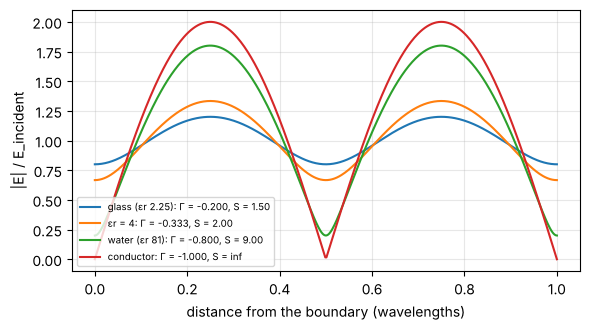

In [2]:
z = np.linspace(0, 1.0, 400)      # in wavelengths
fig, ax = plt.subplots(figsize=(6, 3.4))
for name, eta2 in (('glass (εr 2.25)', eta0 / 1.5), ('εr = 4', eta0 / 2), ('water (εr 81)', eta0 / 9), ('conductor', 0.0)):
    G = (eta2 - eta0) / (eta2 + eta0)
    E = np.abs(np.exp(2j * np.pi * z) + G * np.exp(-2j * np.pi * z))
    S = (1 + abs(G)) / (1 - abs(G)) if abs(G) < 1 else float('inf')
    ax.plot(z, E, label=f"{name}: Γ = {G:+.3f}, S = {S:.2f}")
ax.set_xlabel('distance from the boundary (wavelengths)'); ax.set_ylabel('|E| / E_incident'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 2 · Fresnel reflectance against angle

**Predict first:** from air into glass, at what angle does TM reflection vanish? From glass into air, beyond what angle is everything reflected?

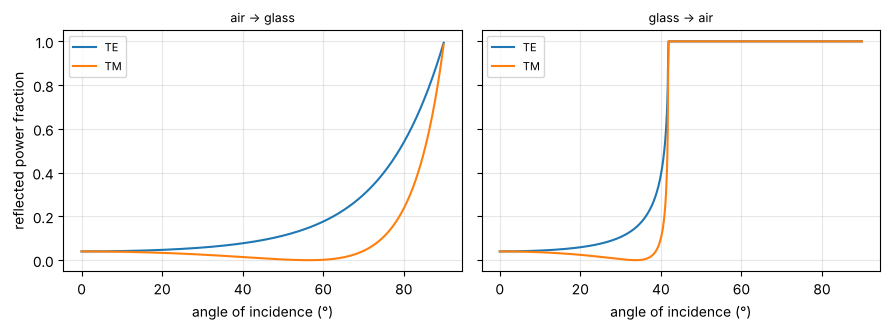

Brewster angle air -> glass: 56.31 deg; glass -> air: 33.69 deg; critical angle glass -> air: 41.81 deg


In [3]:
def fresnel(n1, n2, th):
    s = n1 * np.sin(th) / n2
    ct = np.sqrt(1 - s.astype(complex) ** 2)          # complex beyond the critical angle
    ci = np.cos(th)
    e1, e2 = eta0 / n1, eta0 / n2
    Gte = (e2 * ci - e1 * ct) / (e2 * ci + e1 * ct)
    Gtm = (e2 * ct - e1 * ci) / (e2 * ct + e1 * ci)
    return np.abs(Gte) ** 2, np.abs(Gtm) ** 2

th = np.radians(np.linspace(0, 89.9, 900))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (n1, n2, title) in zip(axes, ((1.0, 1.5, 'air → glass'), (1.5, 1.0, 'glass → air'))):
    Rte, Rtm = fresnel(n1, n2, th)
    ax.plot(np.degrees(th), Rte, label='TE'); ax.plot(np.degrees(th), Rtm, label='TM')
    ax.set_title(title, fontsize=9); ax.set_xlabel('angle of incidence (°)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel('reflected power fraction')
plt.tight_layout(); plt.show()
print(f"Brewster angle air -> glass: {math.degrees(math.atan(1.5)):.2f} deg; glass -> air: {math.degrees(math.atan(1 / 1.5)):.2f} deg; "
      f"critical angle glass -> air: {math.degrees(math.asin(1 / 1.5)):.2f} deg")

## Part 3 · Coatings and radomes

Compute the reflectance of glass with and without a quarter-wave MgF₂ coating across the visible band, and of a half-wave radome ($\varepsilon_r$ = 4, designed for 10 GHz) from 6 to 14 GHz.

**Predict first:** over what band does the radome reflect less than 1% of the power?

radome reflects < 1% from 9.572 to 10.428 GHz: 8.56% bandwidth


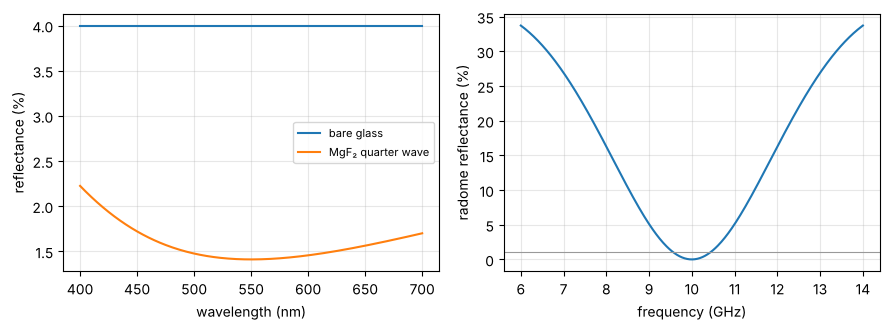

In [4]:
lam = np.linspace(400e-9, 700e-9, 301)
d_c = 550e-9 / (4 * 1.38)
R_bare = [abs(stack(c0 / L, [], eta_out=eta0 / 1.5)[0]) ** 2 for L in lam]
R_coat = [abs(stack(c0 / L, [dielectric(1.38**2, c0 / L, d_c)], eta_out=eta0 / 1.5)[0]) ** 2 for L in lam]
d_r = c0 / (2 * 1e10 * 2)
f = np.linspace(6e9, 14e9, 400)
R_rad = [abs(stack(ff, [dielectric(4, ff, d_r)])[0]) ** 2 for ff in f]
lo = brentq(lambda ff: abs(stack(ff, [dielectric(4, ff, d_r)])[0]) ** 2 - 0.01, 8e9, 1e10)
hi = brentq(lambda ff: abs(stack(ff, [dielectric(4, ff, d_r)])[0]) ** 2 - 0.01, 1e10, 1.2e10)
print(f"radome reflects < 1% from {lo / 1e9:.3f} to {hi / 1e9:.3f} GHz: {100 * (hi - lo) / 1e10:.2f}% bandwidth")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(lam * 1e9, np.array(R_bare) * 100, label='bare glass'); axes[0].plot(lam * 1e9, np.array(R_coat) * 100, label='MgF₂ quarter wave')
axes[0].set_xlabel('wavelength (nm)'); axes[0].set_ylabel('reflectance (%)'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(f / 1e9, np.array(R_rad) * 100); axes[1].axhline(1, color='0.6', lw=0.8)
axes[1].set_xlabel('frequency (GHz)'); axes[1].set_ylabel('radome reflectance (%)'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · Shielding effectiveness of a copper foil

The exact transmission through a 35 µm copper foil, including all internal reflections, against the absorption-plus-reflection estimate.

**Predict first:** at low frequency, where the foil is thinner than a skin depth, is the estimate optimistic or pessimistic?

   1e+05 Hz: exact  111.7 dB, A + R  119.6 dB
   1e+06 Hz: exact  111.7 dB, A + R  112.7 dB
   1e+07 Hz: exact  113.0 dB, A + R  112.7 dB
   1e+08 Hz: exact  134.1 dB, A + R  134.1 dB
   1e+09 Hz: exact  223.6 dB, A + R  223.6 dB
thin-sheet limit 20 log10(1 + eta0 sigma t / 2) = 111.6 dB


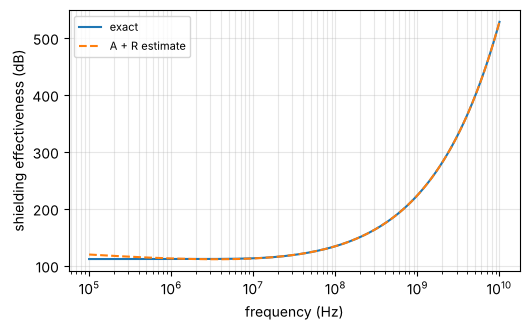

In [5]:
fs = np.logspace(5, 10, 200)
SE = [-20 * math.log10(abs(stack(ff, [metal(5.8e7, ff, 35e-6)])[1])) for ff in fs]
def est(ff):
    eta, k, d = metal(5.8e7, ff, 35e-6)
    return 8.686 * d * abs(k.imag) + 20 * math.log10(eta0 / (4 * abs(eta)))
for ff in (1e5, 1e6, 1e7, 1e8, 1e9):
    print(f"{ff:8.0e} Hz: exact {-20 * math.log10(abs(stack(ff, [metal(5.8e7, ff, 35e-6)])[1])):6.1f} dB, A + R {est(ff):6.1f} dB")
print(f"thin-sheet limit 20 log10(1 + eta0 sigma t / 2) = {20 * math.log10(1 + eta0 * 5.8e7 * 35e-6 / 2):.1f} dB")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.semilogx(fs, SE, label='exact'); ax.semilogx(fs, [est(ff) for ff in fs], '--', label='A + R estimate')
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('shielding effectiveness (dB)'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## What to notice

- A negative Γ puts a field minimum at the boundary; the conductor's minimum is a true zero.
- TM reflection vanishes at the Brewster angle; beyond the critical angle both polarizations reflect totally.
- A single quarter-wave coating works best at its design wavelength; the half-wave radome is transparent only over about 8.6% bandwidth (for less than 1% reflection).
- The A + R estimate is accurate once the foil is several skin depths thick; for thinner foils the internal reflections matter: the estimate is off by up to about a decibel at 1 to 10 MHz and overstates the shielding by about 8 dB at 100 kHz, where the 35 µm foil is a sixth of a skin depth thick. In the thin-sheet limit the exact value tends to $20\log_{10}(1 + \eta_0\sigma t/2)$.